# Front Row: Who Buys the Ticket? — EDA and baseline

**Expected folder layout**
```
data/      train.csv, test.csv, music_app.json, sample_submission.csv
src/       features.py (feature engineering), modeling.py (grouped CV + F1 threshold)
01_eda_baseline.ipynb
```

Notebook outline:
1. Data exploration (CSV + listening JSON)
2. Feature engineering (in `src/features.py`)
3. Model comparison with cross-validation **grouped by user**, with and without listening features
4. F1 threshold selection, final training and submission

In [1]:
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, json, warnings
sys.path.insert(0, 'src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from features import build_features, feature_columns, load_music, CATEGORICAL
from modeling import cv_oof, summarize, best_threshold
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
DATA = 'data'

OSError: dlopen(/Users/gabriel/Downloads/kaggle-concerts/.venv/lib/python3.15/site-packages/lightgbm/lib/lib_lightgbm.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib
  Referenced from: <59CCDAC2-EBAE-32F7-ADF4-469B834532C9> /Users/gabriel/Downloads/kaggle-concerts/.venv/lib/python3.15/site-packages/lightgbm/lib/lib_lightgbm.dylib
  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libomp/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libomp/libomp.dylib' (no such file)

## 1. Exploration
### 1.1 The CSV files

In [ ]:
train = pd.read_csv(f'{DATA}/train.csv'); test = pd.read_csv(f'{DATA}/test.csv')
print(train.shape, test.shape)
print('Overall purchase rate:', round(train.buy.mean(), 4))
print('Users shared by train/test:', len(set(train.user_id) & set(test.user_id)))
train.head(3).T

(30000, 32) (20000, 31)
Overall purchase rate: 0.3362
Users shared by train/test: 0


,0,1,2
row_id,R2F019957,R0804D93A,R367FE81E
user_id,U2CFDCAAD,U1FC01010,U0C605712
music_app_user_id,M1B01D2D7,M1B2C63CC,M3AEF638D
age,23,51,32
education,postgraduate,undergraduate,secondary
spending_capacity_band,2,5,1
home_city,Nantes,Bordeaux,Lyon
home_lat,47.218,44.838,45.764
home_lon,-1.554,-0.579,4.835
stated_favourite_genre,pop,pop,classical


In [ ]:
# Missing values (a blank is not a zero!)
na = train.isna().mean(); na[na > 0].sort_values(ascending=False).to_frame('missing_share')

,missing_share
travel_search_arrival,0.749867
travel_search_city,0.749867
typical_ticket_spend,0.274667
usual_booking_lead_days,0.274667
stated_favourite_genre,0.154167
music_app_user_id,0.056500
event_page_visits_7d,0.028767


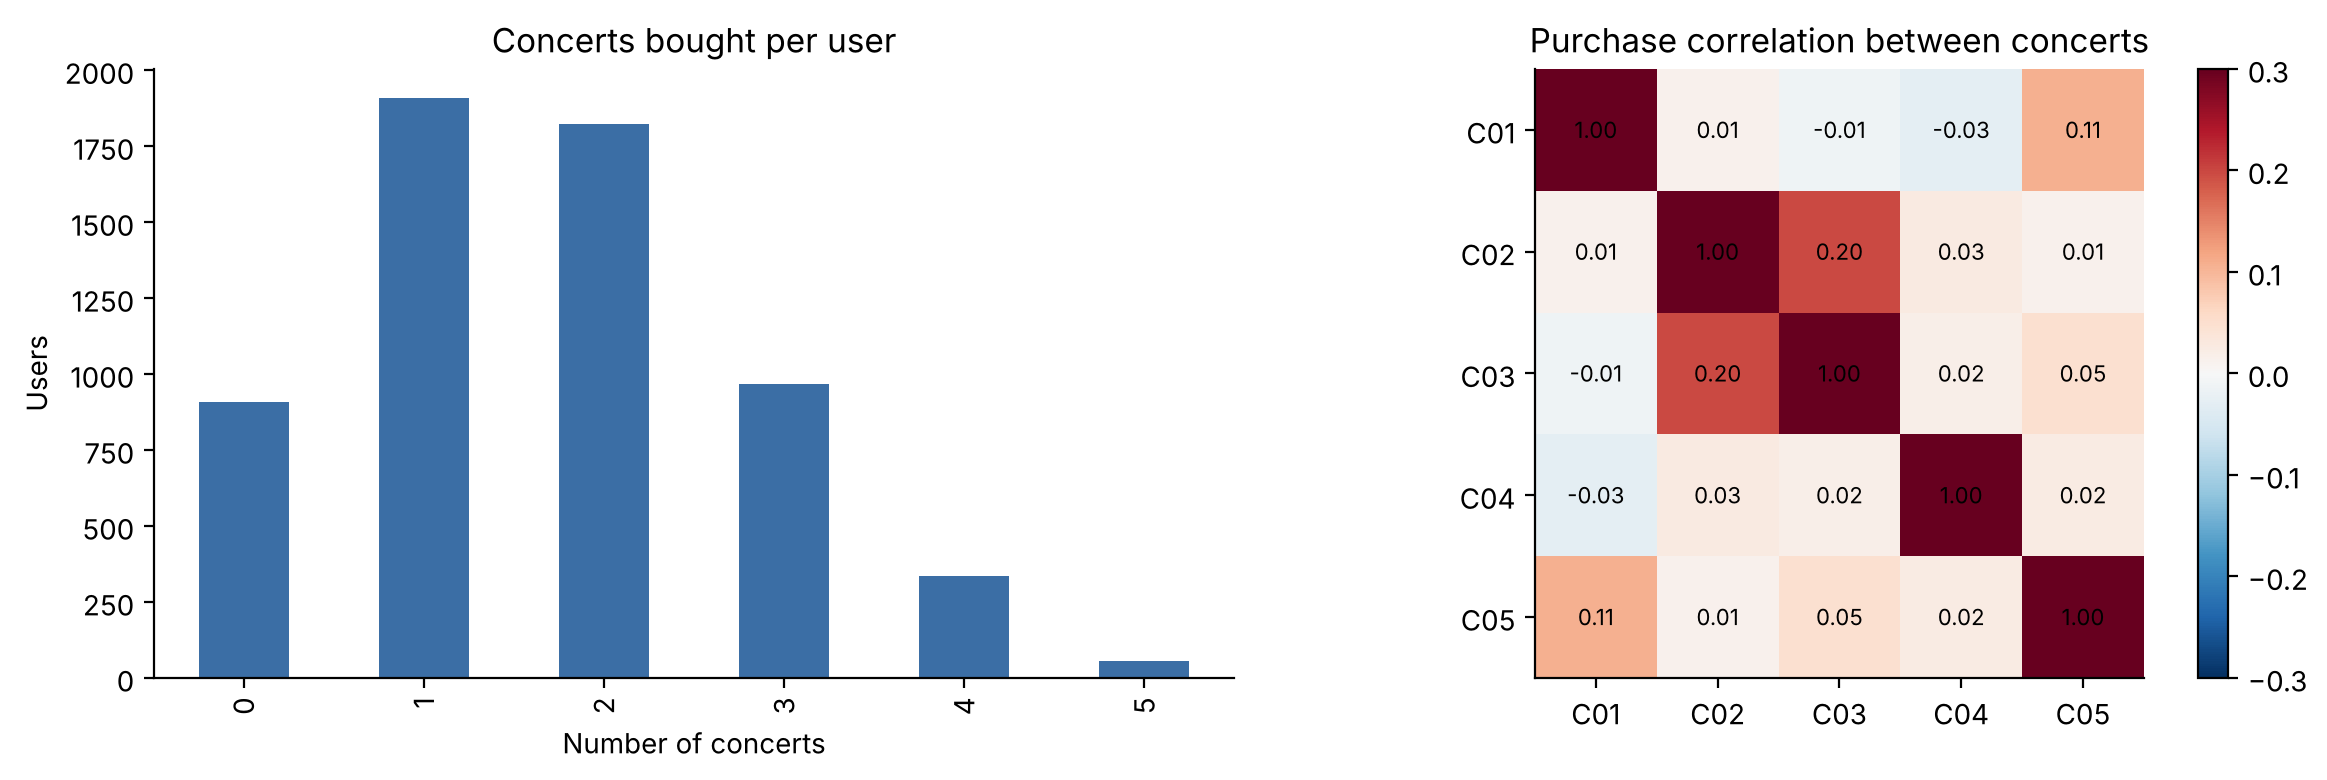

In [ ]:
# Concerts bought per user, and correlation of purchases across concerts
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train.groupby('user_id').buy.sum().value_counts().sort_index().plot.bar(ax=ax[0], color='#3b6ea5')
ax[0].set(title='Concerts bought per user', xlabel='Number of concerts', ylabel='Users')
corr = train.pivot_table(index='user_id', columns='concert_id', values='buy').corr()
im = ax[1].imshow(corr, cmap='RdBu_r', vmin=-.3, vmax=.3)
ax[1].set_xticks(range(5), corr.columns); ax[1].set_yticks(range(5), corr.index)
for i in range(5):
    for j in range(5): ax[1].text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
ax[1].set_title('Purchase correlation between concerts'); plt.colorbar(im, ax=ax[1]); plt.tight_layout()

About 34% of rows are positive. Purchases are mostly independent across concerts, except C02 (Olivia Rodrigo) with C03 (Taylor Swift), and C01 (Kendrick Lamar) with C05 (SZA). These pairs share similar genres.

### 1.2 The listening JSON

In [ ]:
events, status, artist_genres = load_music(f'{DATA}/music_app.json')
print(status.value_counts())
print(f'{len(events):,} track events, {events.mid.nunique():,} active accounts')
events.head()

app_status
active     8746
empty       379
missing     307
Name: count, dtype: int64
551,901 track events, 8,746 active accounts


,mid,session_id,played_at,artist_id,genre,track_id,played_ms,track_ms,searched,saved,days_ago,completion,completed,skipped
0,M1213C172,S001,2026-09-30 21:22:16+00:00,A11,alternative,A11_6,132490,160000,False,False,0.109537,0.828063,False,False
1,M1213C172,S002,2026-09-29 00:22:53+00:00,A08,jazz_funk,A08_6,198000,198000,False,False,1.984109,1.000000,True,False
2,M1213C172,S003,2026-09-28 00:42:34+00:00,A08,jazz_funk,A08_12,223698,273000,True,True,2.970440,0.819407,False,False
3,M1213C172,S003,2026-09-28 17:59:57+00:00,A11,alternative,A11_12,205737,232000,True,False,2.250035,0.886797,False,False
4,M1213C172,S004,2026-09-27 21:36:03+00:00,A16,metal,A16_10,180541,196000,True,False,3.099965,0.921128,True,False


artist_id
A03    41902
A01    37232
A12    36690
A11    35653
A05    35412
A14    35263
A13    35083
A06    34114
A07    33794
A08    33664
A02    32941
A15    32730
A10    32722
A16    32645
A09    32123
A04    29933
dtype: int64


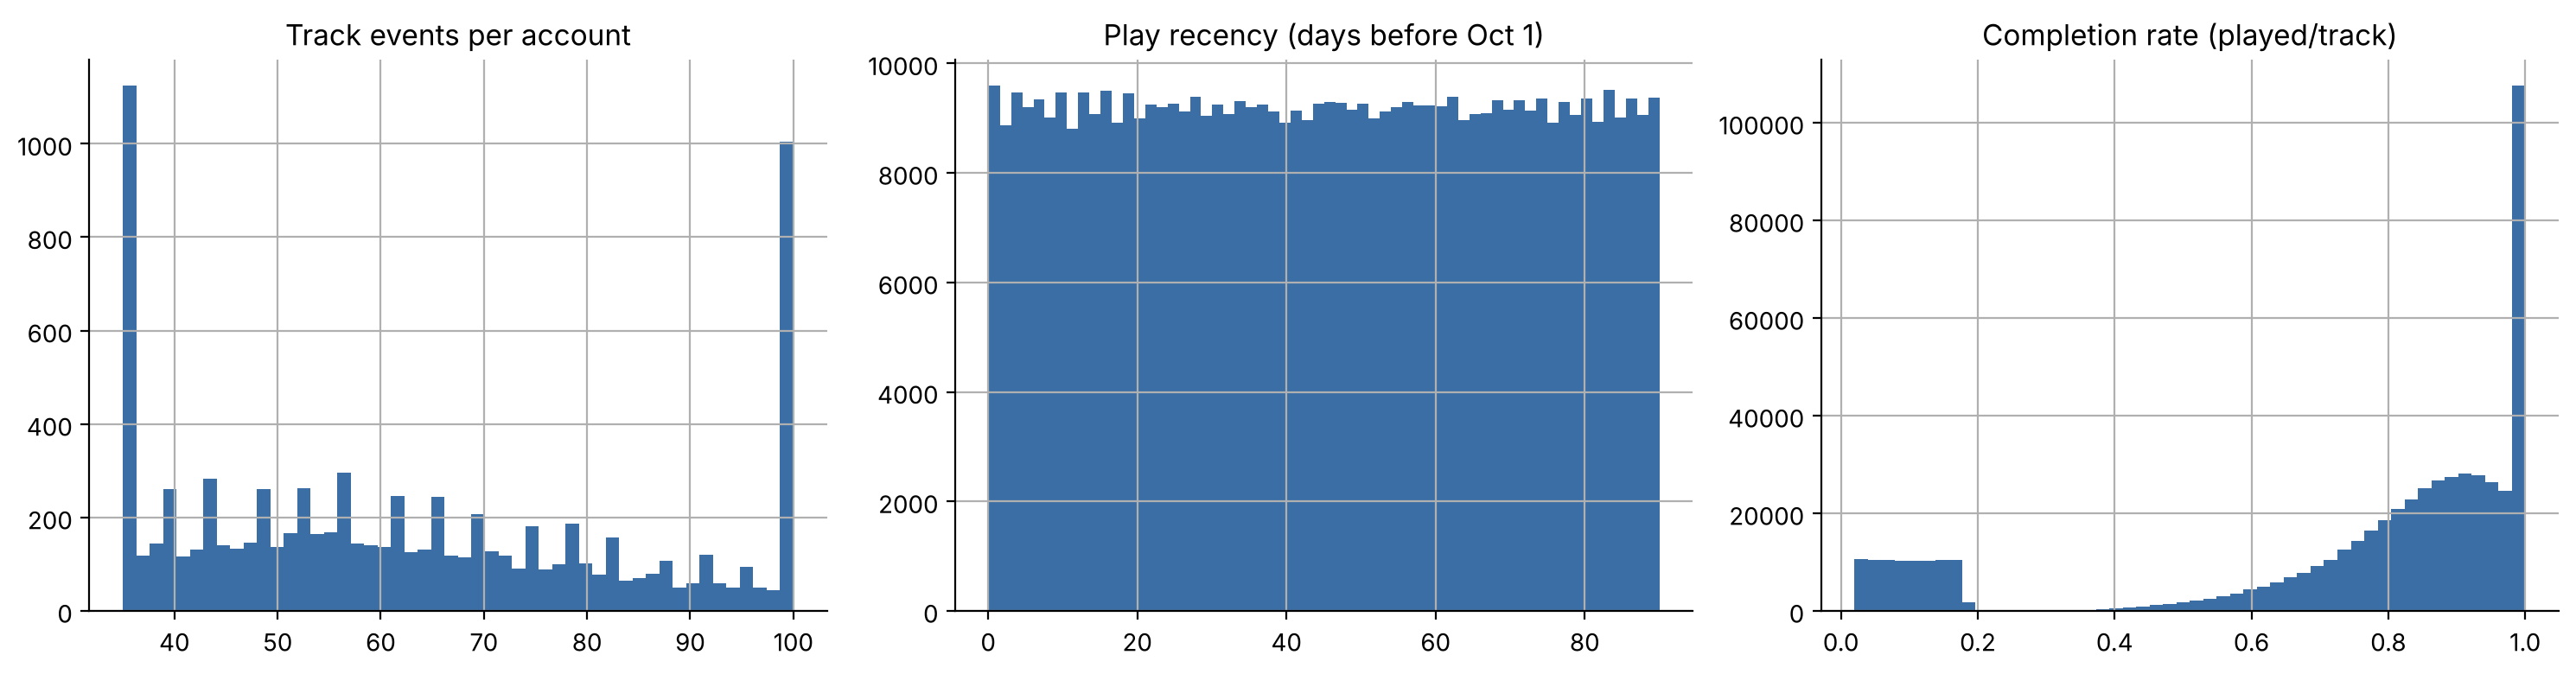

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
events.groupby('mid').size().clip(upper=1000).hist(bins=50, ax=ax[0], color='#3b6ea5'); ax[0].set_title('Track events per account')
events.days_ago.hist(bins=60, ax=ax[1], color='#3b6ea5'); ax[1].set_title('Play recency (days before Oct 1)')
events.completion.hist(bins=50, ax=ax[2], color='#3b6ea5'); ax[2].set_title('Completion rate (played/track)')
plt.tight_layout()
print(events.groupby('artist_id').size().sort_values(ascending=False).head(16))

## 2. Feature engineering
Everything lives in `src/features.py` (commented). Feature families:
- **Offer**: total cost, cost / usual spend, discount, home–venue distance, same city, days to concert vs usual booking lead time.
- **Engagement**: page visits, wishlist, travel search *to the venue city* and *around the concert date*, per-user aggregates over the 5 offers.
- **Account status**: 4 distinct cases (unlinked / active / empty / missing).
- **User listening**: volume, sessions, search share, save share, completion, recency.
- **User × concert artist**: plays, share of plays, searches, saves, completion, distinct tracks, recency, weighted score, **rank of the artist among the 5**.
- **User × concert genres**: share of listening time in the concert's genres.

In [ ]:
tr, te = build_features(DATA)
print(tr.shape, te.shape)

(30000, 96) (20000, 95)


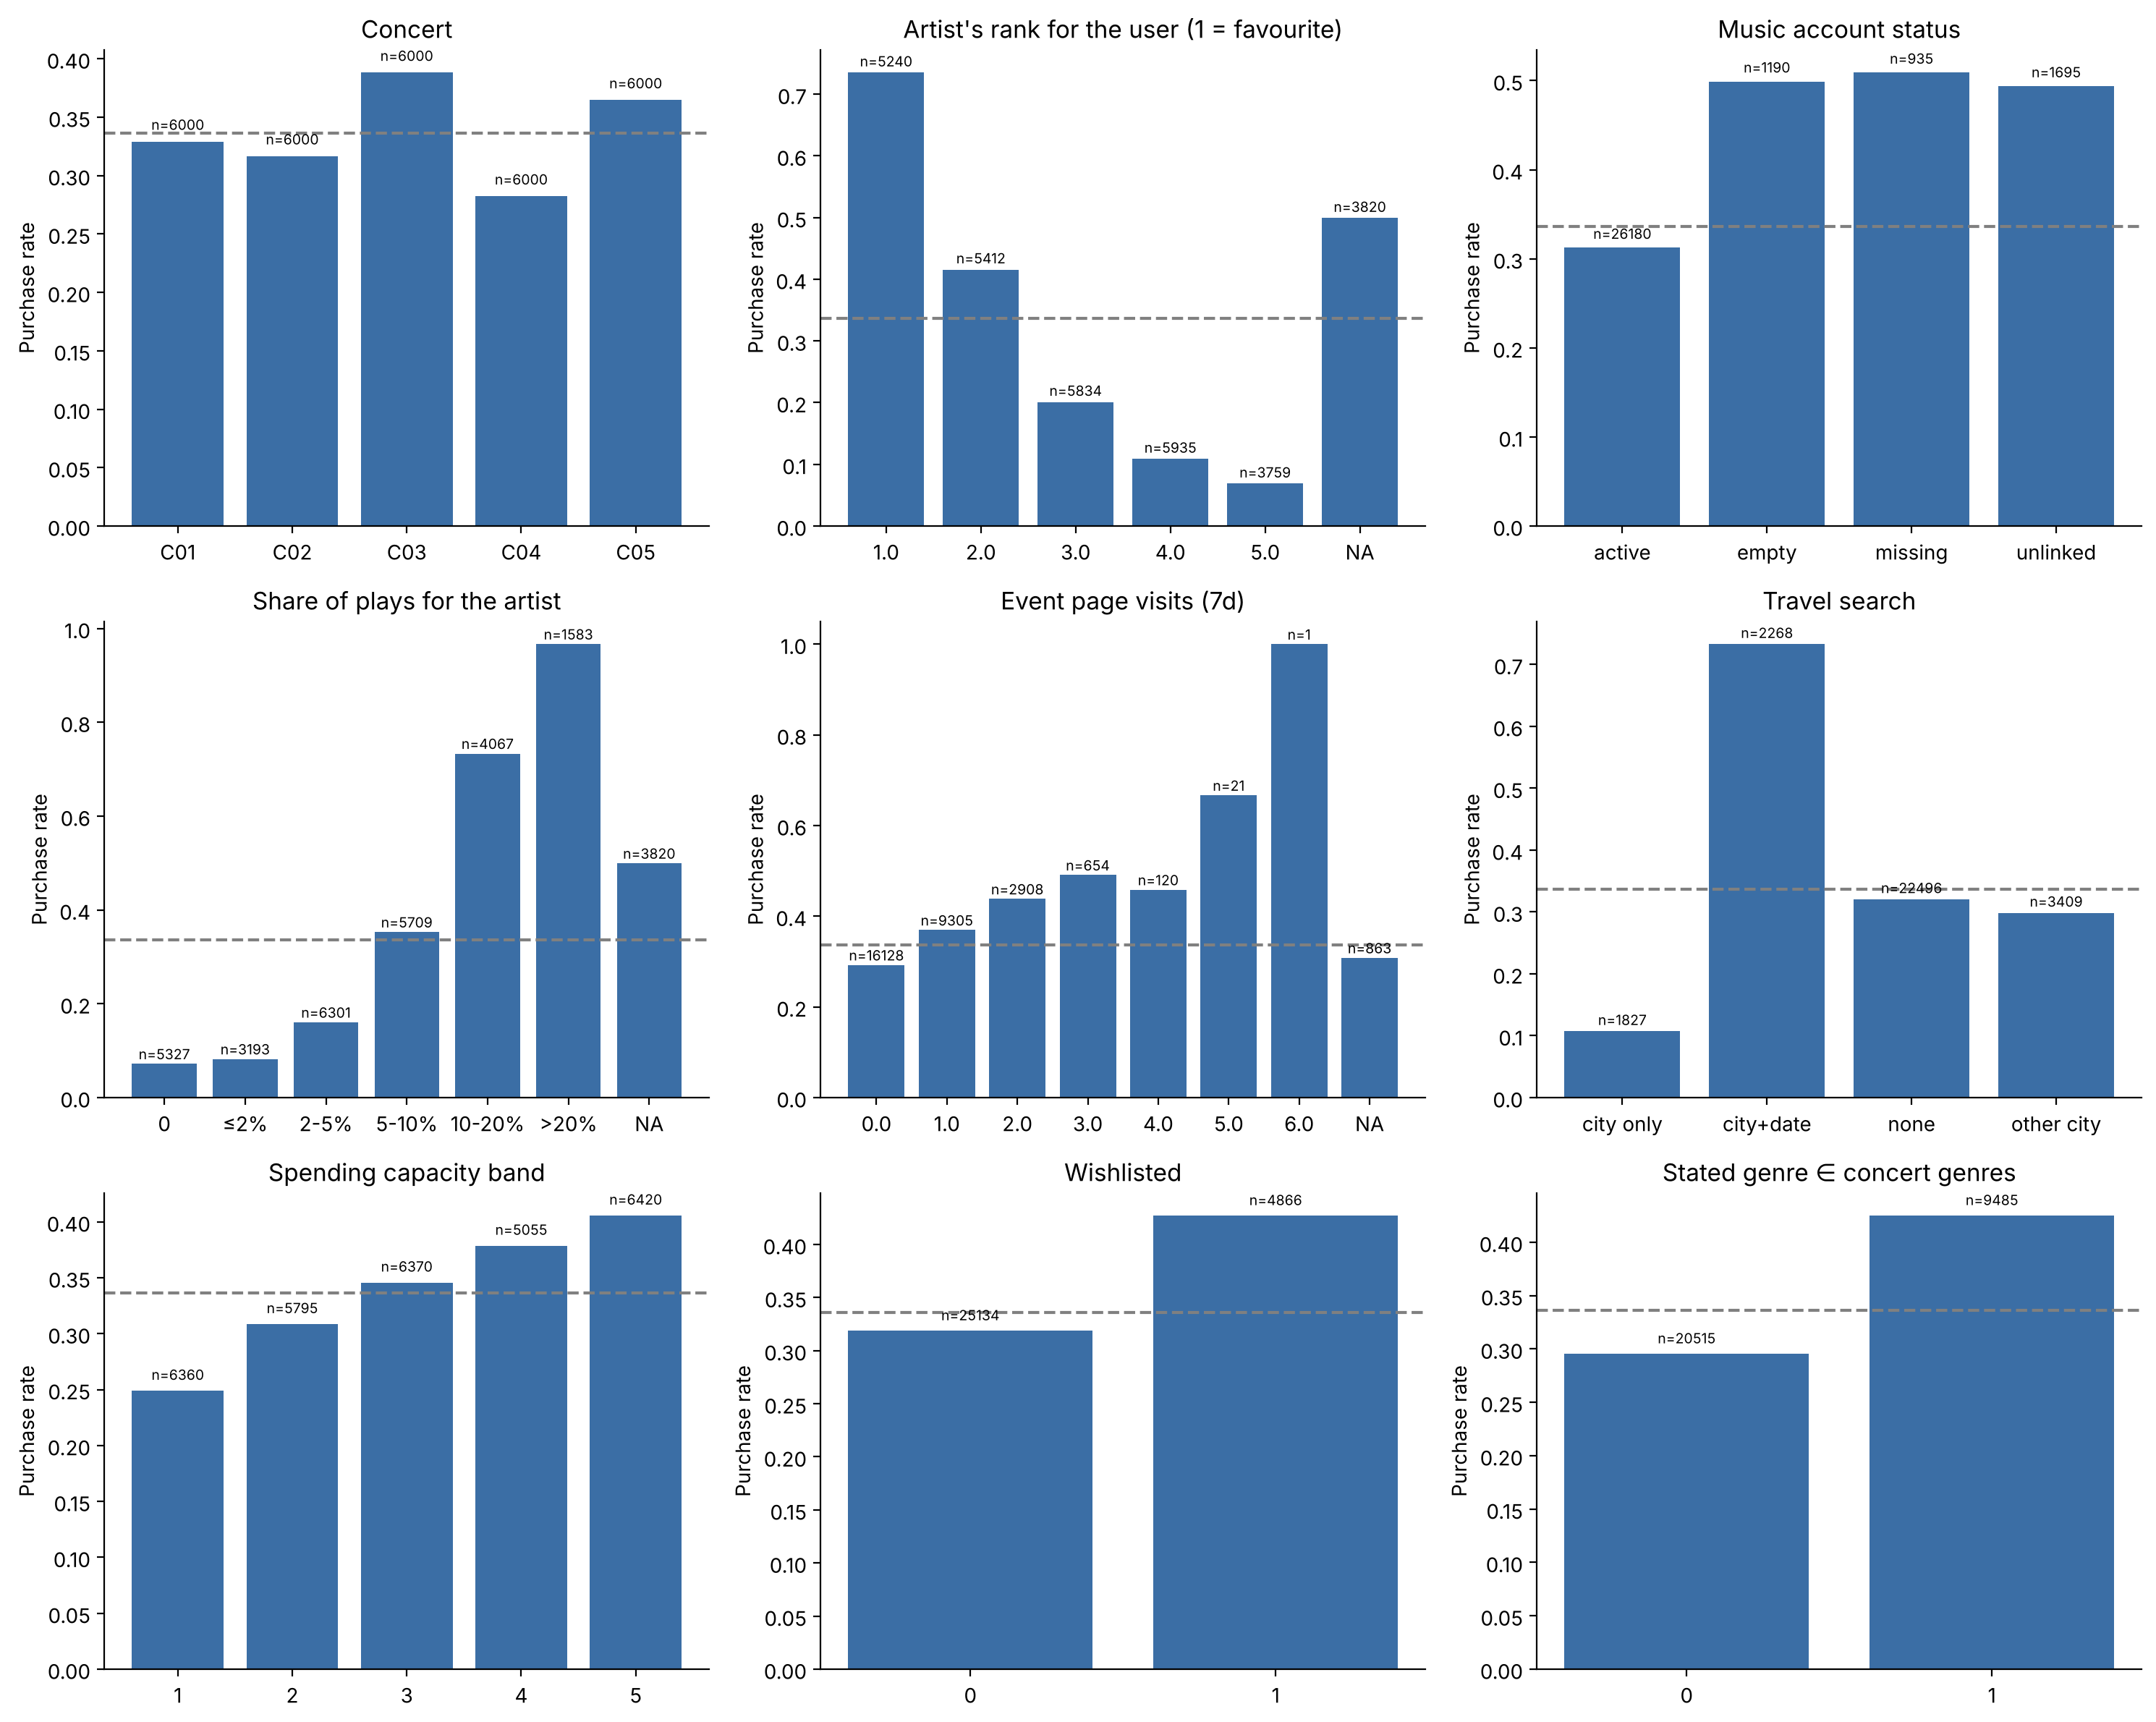

In [ ]:
def bar(ax, col, title):
    m = tr.groupby(col, dropna=False).buy.agg(['mean', 'size'])
    lab = ['NA' if (isinstance(i, float) and np.isnan(i)) else str(i) for i in m.index]
    ax.bar(lab, m['mean'], color='#3b6ea5'); ax.axhline(tr.buy.mean(), ls='--', c='gray')
    ax.set_title(title); ax.set_ylabel('Purchase rate')
    for i, (v, n) in enumerate(zip(m['mean'], m['size'])): ax.text(i, v + .01, f'n={n}', ha='center', fontsize=7)

tr['_share'] = pd.cut(tr.a_share_tracks, [-1e-9, 0, .02, .05, .1, .2, 1], labels=['0', '≤2%', '2-5%', '5-10%', '10-20%', '>20%'])
tr['_travel'] = np.select([tr.travel_match_date == 1, tr.travel_to_venue == 1, tr.has_travel_search == 1],
                          ['city+date', 'city only', 'other city'], 'none')
fig, axs = plt.subplots(3, 3, figsize=(15, 12))
for ax, (c, t) in zip(axs.flat, [('concert_id', 'Concert'), ('a_rank_in_user', "Artist's rank for the user (1 = favourite)"),
        ('app_status', 'Music account status'), ('_share', 'Share of plays for the artist'),
        ('event_page_visits_7d', 'Event page visits (7d)'), ('_travel', 'Travel search'),
        ('spending_capacity_band', 'Spending capacity band'), ('wishlisted', 'Wishlisted'), ('fav_genre_in_concert', 'Stated genre ∈ concert genres')]):
    bar(ax, c, t)
plt.tight_layout(); tr = tr.drop(columns=['_share', '_travel'])

**Key takeaways:**
- **Artist affinity dominates.** Users buy 73% of the time for their favourite of the 5 artists, versus 7% for their 5th. Above 20% of plays devoted to the artist, the purchase rate reaches 97%.
- **Account status matters.** Users with no history (unlinked, empty or missing) buy about 50% of the time, versus 31% for active accounts. These blanks must not be filled with 0.
- **Travel search only helps when both city AND date match the concert** (73%). The right city on another date gives 11%, lower than having no search at all.
- Page visits, wishlist, spending capacity and stated genre have a moderate effect.

## 3. Model comparison (5-fold CV grouped by `user_id`)
Each model is evaluated **with and without** the listening features to measure their contribution (report Section 1).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

y, groups = tr.buy, tr.user_id
LGB_PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, verbose=-1, random_state=0)

def prepare(df, cols):
    X = df[cols].copy(); cats = [c for c in CATEGORICAL if c in cols]
    for c in cats: X[c] = X[c].astype('category')
    Xs = X.copy()  # string version for sklearn
    for c in cats: Xs[c] = Xs[c].astype(str).replace('nan', 'NA')
    return X, Xs, cats, [c for c in cols if c not in cats]

results, oofs = [], {}
for music in [False, True]:
    tag = 'CSV+listening' if music else 'CSV only'
    cols = feature_columns(tr, music); X, Xs, cats, nums = prepare(tr, cols)
    ohe = make_pipeline(SimpleImputer(strategy='constant', fill_value='NA'), OneHotEncoder(handle_unknown='ignore'))
    models = {
        # Logistic regression: median imputation + missing indicators, standardisation
        'LogReg': lambda: make_pipeline(make_column_transformer(
            (make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), nums), (ohe, cats)),
            LogisticRegression(C=0.5, max_iter=3000)),
        # Random Forest: missing values encoded as -999 (trees can isolate this value)
        'RandomForest': lambda: make_pipeline(make_column_transformer(
            (SimpleImputer(strategy='constant', fill_value=-999), nums), (ohe, cats)),
            RandomForestClassifier(300, min_samples_leaf=5, max_features=0.3, n_jobs=-1, random_state=0)),
    }
    for name, mk in models.items():
        oof, auc = cv_oof(mk, Xs, y, groups); results.append(summarize(f'{name} | {tag}', y, oof, auc))
    # LightGBM handles NaN and categoricals natively
    oof, auc = cv_oof(lambda: lgb.LGBMClassifier(**LGB_PARAMS), X, y, groups)
    results.append(summarize(f'LightGBM | {tag}', y, oof, auc)); oofs[tag] = oof
res = pd.DataFrame(results).round(4); res

,model,cv_auc,cv_auc_std,best_threshold,cv_f1
0,LogReg | CSV only,0.7303,0.0070,0.300,0.5768
1,RandomForest | CSV only,0.7345,0.0047,0.315,0.5799
2,LightGBM | CSV only,0.7436,0.0038,0.285,0.5856
3,LogReg | CSV+listening,0.9452,0.0020,0.400,0.8167
4,RandomForest | CSV+listening,0.9457,0.0020,0.430,0.8225
5,LightGBM | CSV+listening,0.9583,0.0020,0.425,0.8404


Listening features lift F1 from about 0.58 to about 0.84, whatever the model. LightGBM is the best of the three.

⚠️ The threshold is chosen on the same out-of-fold predictions used to compute the reported F1, so the score is very slightly optimistic. This is negligible here: a single parameter tuned on 30,000 rows.

## 4. Decision threshold, feature importance, submission

Text(0, 0.5, 'F1')

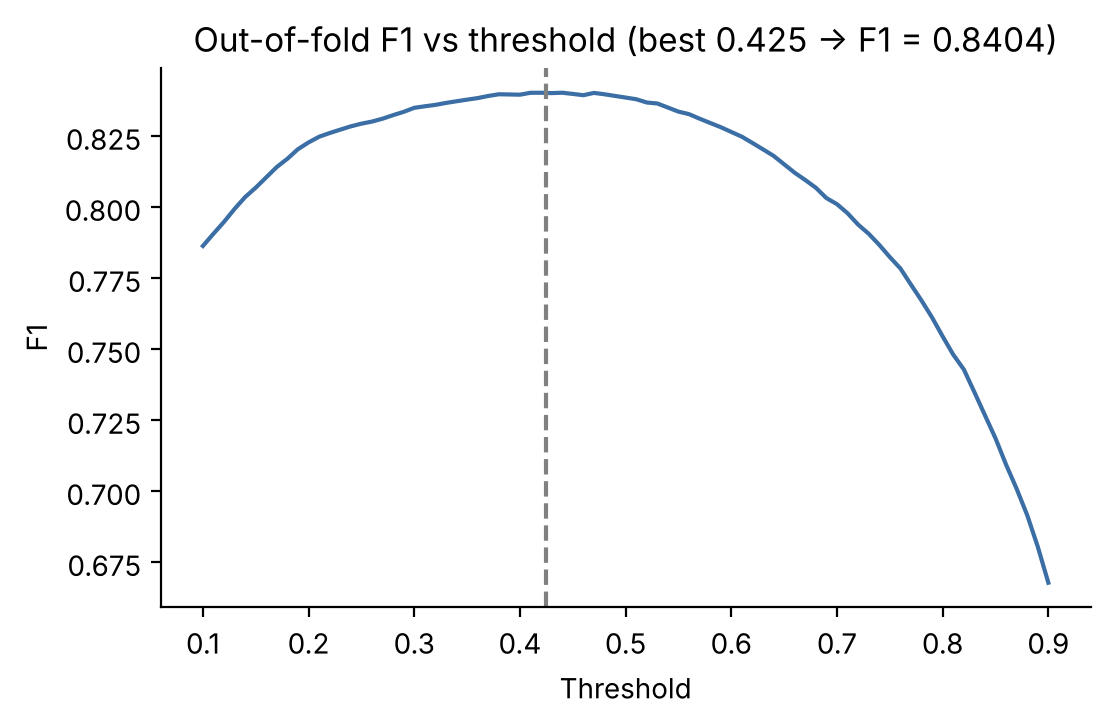

In [ ]:
oof = oofs['CSV+listening']
grid = np.linspace(0.1, 0.9, 81)
from sklearn.metrics import f1_score
plt.figure(figsize=(6, 3.5)); plt.plot(grid, [f1_score(y, oof >= t) for t in grid], color='#3b6ea5')
t_best, f1_best = best_threshold(y, oof); plt.axvline(t_best, ls='--', c='gray')
plt.title(f'Out-of-fold F1 vs threshold (best {t_best:.3f} → F1 = {f1_best:.4f})'); plt.xlabel('Threshold'); plt.ylabel('F1')

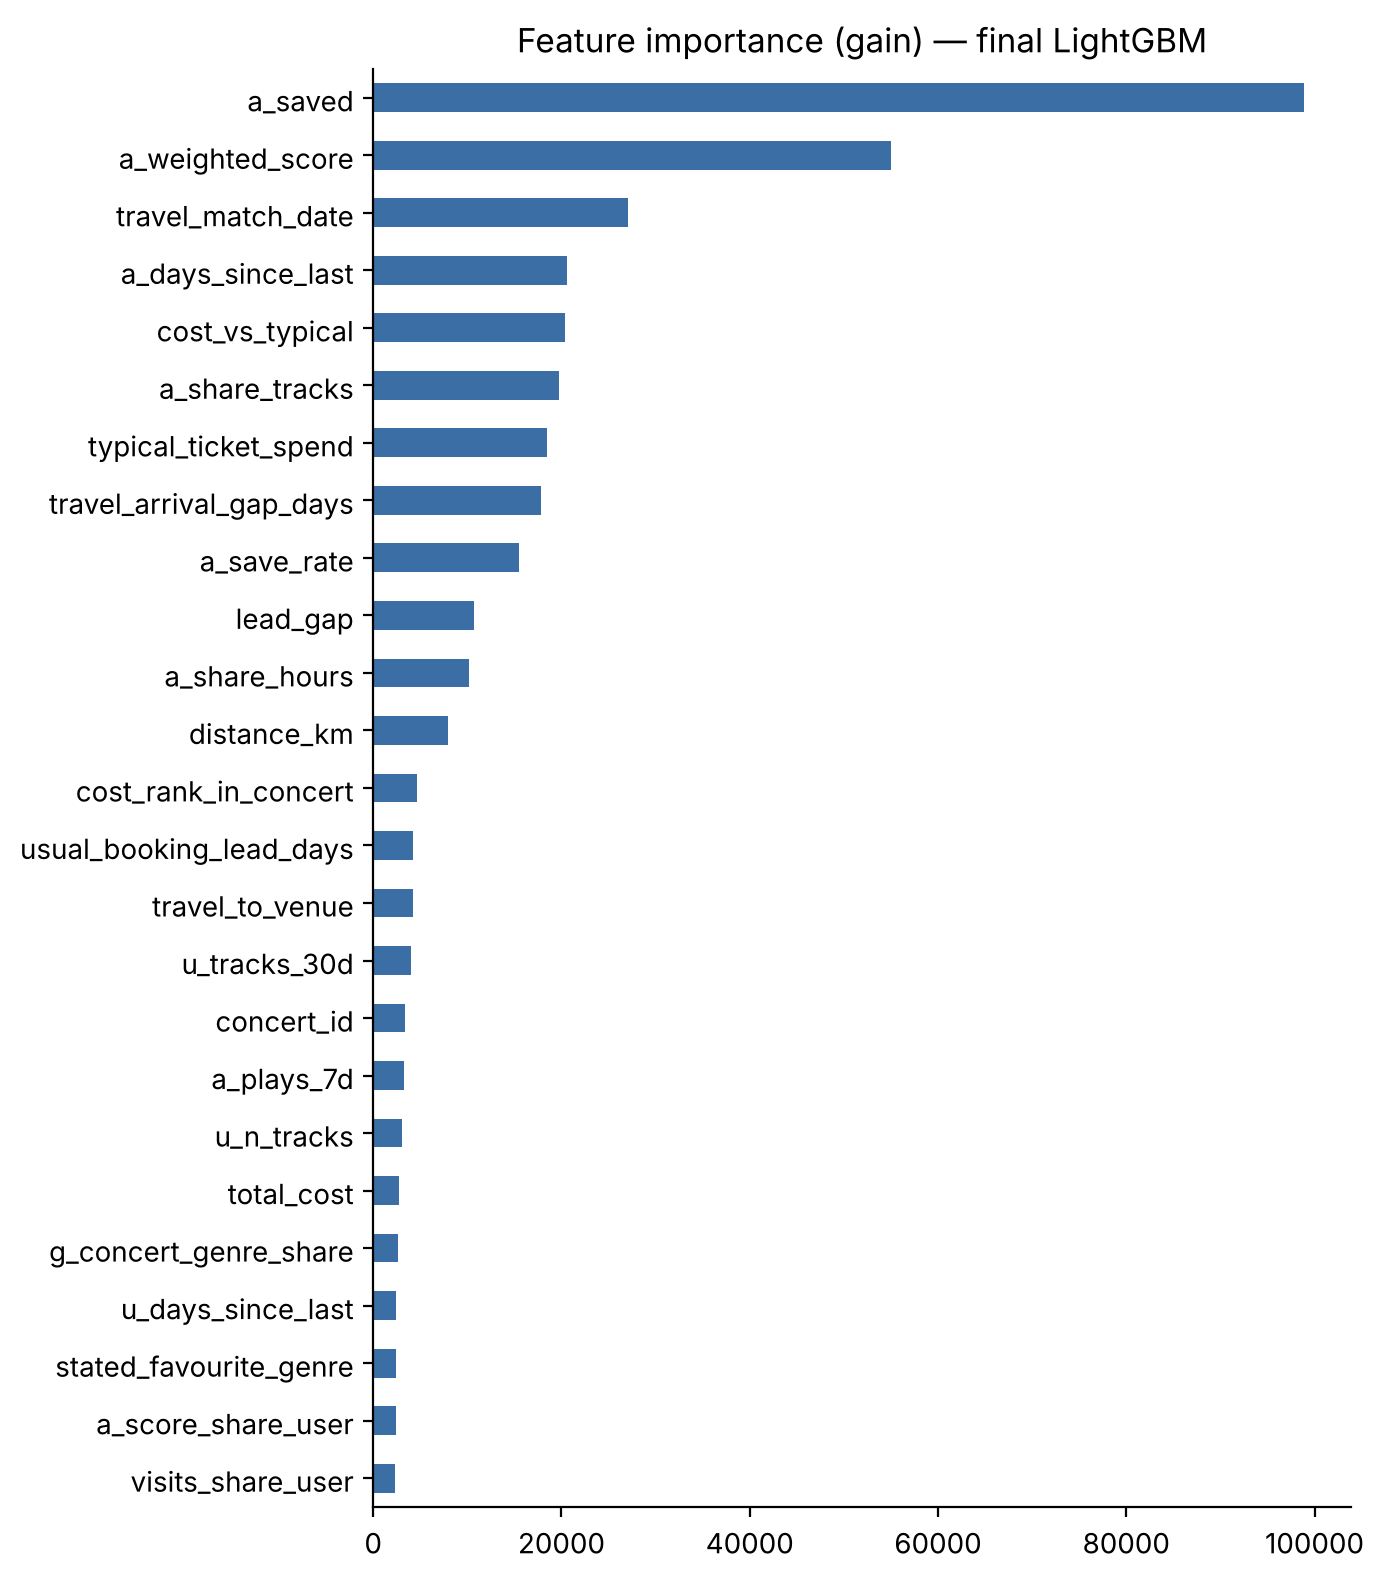

In [ ]:
cols = feature_columns(tr, True); X, _, _, _ = prepare(tr, cols)
final = lgb.LGBMClassifier(**LGB_PARAMS).fit(X, y)
imp = pd.Series(final.booster_.feature_importance('gain'), index=cols).sort_values()
imp.tail(25).plot.barh(figsize=(7, 8), color='#3b6ea5', title='Feature importance (gain) — final LightGBM'); plt.tight_layout()

In [ ]:
Xte, _, _, _ = prepare(te, cols)
# same categories as in train
for c in X.select_dtypes('category'): Xte[c] = pd.Categorical(Xte[c], categories=X[c].cat.categories)
p_test = final.predict_proba(Xte)[:, 1]
sub = pd.DataFrame({'row_id': te.row_id, 'buy': (p_test >= t_best).astype(int)})
sample = pd.read_csv(f'{DATA}/sample_submission.csv')
assert len(sub) == 20000 and set(sub.row_id) == set(sample.row_id)
sub = sample[['row_id']].merge(sub, on='row_id')  # same order as the sample file
sub.to_csv('submission_lgbm_baseline.csv', index=False)
print('Predicted positive rate — test:', sub.buy.mean().round(4), '| OOF train:', (oof >= t_best).mean().round(4))

Predicted positive rate — test: 0.3522 | OOF train: 0.3503


## Next steps
- **Features**: trend in artist listening (last 30 days vs the previous 30, to catch rising interest before the concert); plays of "Library" artists in the same genres; cost × spending-capacity interactions; travel search combined with artist affinity.
- **Models**: LightGBM tuning (Optuna, same grouped CV), XGBoost / CatBoost, ensembling or stacking, possibly a per-concert threshold.
- **Report**: feature-family ablations (drop one family, measure the F1 loss), building on the table above.